In [1]:
import sys
sys.path.append("..")  # so the notebook can see the src/ folder

from src.data_loading import load_secom

%load_ext autoreload
%autoreload 2

df = load_secom("../data/raw")
print(df.shape)
print(df["label"].value_counts())

(1567, 592)
label
-1    1463
 1     104
Name: count, dtype: int64


In [2]:
missing_pct = df.drop(columns=["label", "timestamp"]).isna().mean().sort_values(ascending=False)
print(missing_pct.describe())
print(missing_pct.head(35))

count    590.000000
mean       0.045375
std        0.154340
min        0.000000
25%        0.001276
50%        0.003829
75%        0.005743
max        0.911934
dtype: float64
sensor_292    0.911934
sensor_293    0.911934
sensor_158    0.911934
sensor_157    0.911934
sensor_492    0.855775
sensor_85     0.855775
sensor_358    0.855775
sensor_220    0.855775
sensor_244    0.649649
sensor_517    0.649649
sensor_109    0.649649
sensor_246    0.649649
sensor_383    0.649649
sensor_382    0.649649
sensor_384    0.649649
sensor_245    0.649649
sensor_111    0.649649
sensor_110    0.649649
sensor_516    0.649649
sensor_518    0.649649
sensor_580    0.605616
sensor_578    0.605616
sensor_579    0.605616
sensor_581    0.605616
sensor_73     0.506701
sensor_345    0.506701
sensor_72     0.506701
sensor_346    0.506701
sensor_519    0.456286
sensor_247    0.456286
sensor_385    0.456286
sensor_112    0.456286
sensor_563    0.174218
sensor_564    0.174218
sensor_565    0.174218
dtype: float64


In [3]:
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    print(f"threshold {t:.0%}: {(missing_pct > t).sum()} columns would be dropped")

threshold 5%: 52 columns would be dropped
threshold 10%: 52 columns would be dropped
threshold 15%: 52 columns would be dropped
threshold 20%: 32 columns would be dropped
threshold 30%: 32 columns would be dropped
threshold 50%: 28 columns would be dropped


In [4]:
from src.data_loading import clean_secom
df_clean, cleaning_stats = clean_secom(df)
print(cleaning_stats)

df_clean.to_csv("../data/processed/secom_eda_clean.csv", index=False)

{'dropped_high_missing': 32, 'dropped_zero_variance': 116}


sensor_59     0.156008
sensor_103    0.151230
sensor_510    0.131662
sensor_348    0.130807
sensor_431    0.119936
sensor_434    0.111312
sensor_430    0.109115
sensor_21     0.108333
sensor_435    0.108260
sensor_28     0.106987
dtype: float64


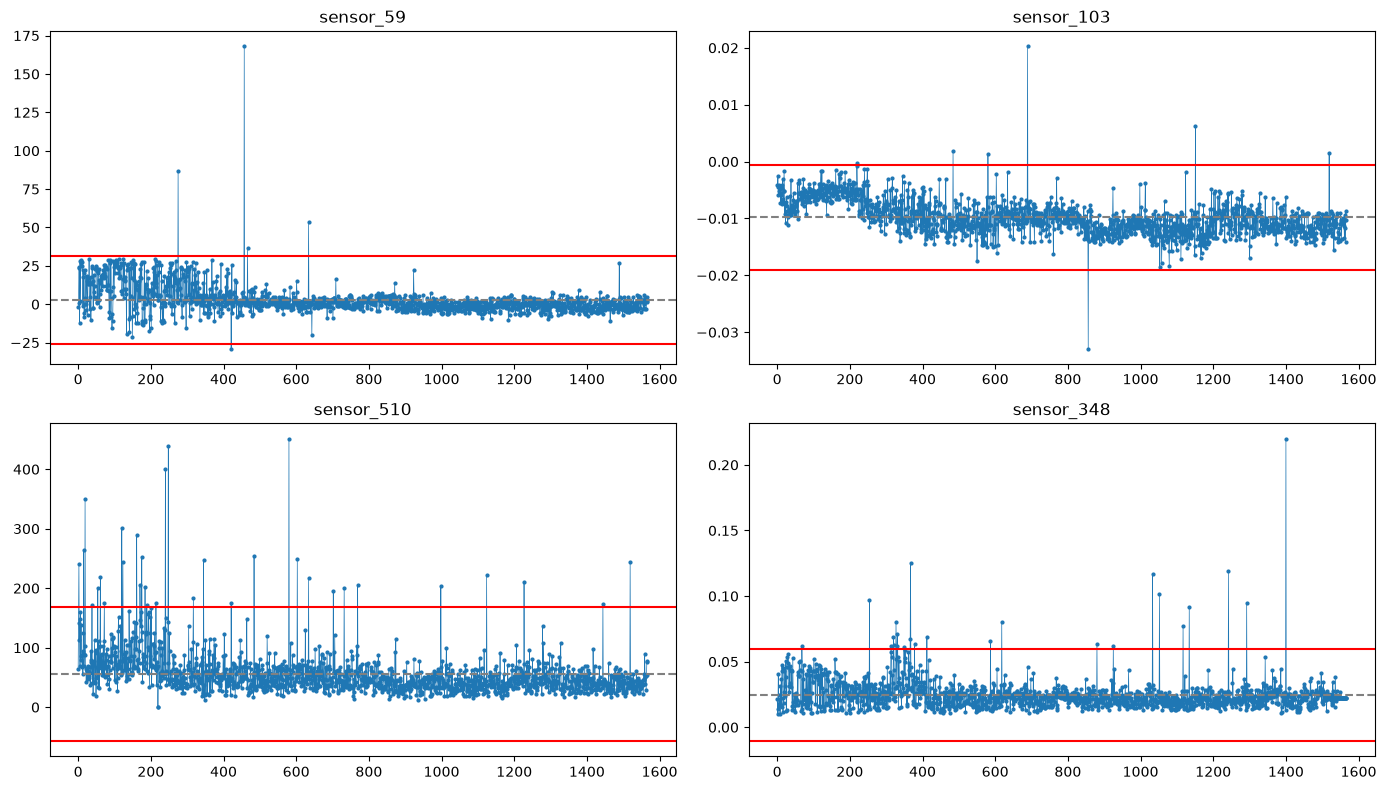

In [5]:
import matplotlib.pyplot as plt

feature_cols = df_clean.drop(columns=["label", "timestamp"]).columns
corrs = df_clean[feature_cols].apply(lambda col: col.corr(df_clean["label"])).abs().sort_values(ascending=False)
print(corrs.head(10))

top_sensors = corrs.head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, sensor in zip(axes.flat, top_sensors):
    mean, std = df_clean[sensor].mean(), df_clean[sensor].std()
    ax.plot(df_clean[sensor].values, marker='o', markersize=2, linewidth=0.5)
    ax.axhline(mean, linestyle='--', color='gray')
    ax.axhline(mean + 3*std, color='red')
    ax.axhline(mean - 3*std, color='red')
    ax.set_title(sensor)
plt.tight_layout()
plt.savefig("../reports/figures/spc_top_sensors.png", dpi=150)
plt.show()